In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "../data/processed/online_retail_product_sales.csv",
    dtype={"InvoiceNo": str, "StockCode": str},
    parse_dates=["InvoiceDate"],
    low_memory=False
)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Dataset shape: (521917, 9)

Columns:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Revenue']


In [2]:
top_products = ["85123A", "85099B", "22423", "47566", "20725"]

product_df = df[df["StockCode"].isin(top_products)].copy()

monthly_product_analysis = (
    product_df
    .groupby([
        "StockCode",
        "Description",
        pd.Grouper(key="InvoiceDate", freq="MS")
    ])
    .agg(
        transaction_count=("InvoiceNo", "nunique"),
        quantity_sold=("Quantity", "sum"),
        revenue=("Revenue", "sum"),
        average_unit_price=("UnitPrice", "mean")
    )
    .reset_index()
)

monthly_product_analysis["weighted_average_price"] = (
    monthly_product_analysis["revenue"]
    / monthly_product_analysis["quantity_sold"]
)

display(monthly_product_analysis.round(2))

C:\Users\hiba3\AppData\Local\Temp\ipykernel_1712\3990326199.py:26: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(monthly_product_analysis.round(2))


,StockCode,Description,InvoiceDate,transaction_count,quantity_sold,revenue,average_unit_price,weighted_average_price
0,20725,LUNCH BAG RED RETROSPOT,2010-12-01,85,731,1445.74,2.67,1.98
1,20725,LUNCH BAG RED RETROSPOT,2011-01-01,86,1388,2242.25,2.27,1.62
2,20725,LUNCH BAG RED RETROSPOT,2011-02-01,105,1158,2029.12,2.55,1.75
3,20725,LUNCH BAG RED RETROSPOT,2011-03-01,119,1504,2740.77,2.21,1.82
4,20725,LUNCH BAG RED RETROSPOT,2011-04-01,111,1125,2406.94,2.01,2.14
...,...,...,...,...,...,...,...,...
62,85123A,WHITE HANGING HEART T-LIGHT HOLDER,2011-08-01,143,2075,5620.57,3.01,2.71
63,85123A,WHITE HANGING HEART T-LIGHT HOLDER,2011-09-01,171,2474,6945.66,3.13,2.81
64,85123A,WHITE HANGING HEART T-LIGHT HOLDER,2011-10-01,157,1685,4750.15,3.21,2.82
65,85123A,WHITE HANGING HEART T-LIGHT HOLDER,2011-11-01,250,4908,14130.80,3.16,2.88


In [3]:
description_check = (
    product_df.groupby("StockCode")["Description"]
    .nunique()
    .reset_index(name="unique_descriptions")
)

display(description_check)


,StockCode,unique_descriptions
0,20725,2
1,22423,1
2,47566,1
3,85099B,1
4,85123A,2


In [4]:
for code in ["20725", "85123A"]:
    print(f"\nStockCode: {code}")
    print(
        product_df.loc[
            product_df["StockCode"] == code,
            "Description"
        ].value_counts(dropna=False)
    )


StockCode: 20725
Description
LUNCH BAG RED RETROSPOT    1577
LUNCH BAG RED SPOTTY          1
Name: count, dtype: int64

StockCode: 85123A
Description
WHITE HANGING HEART T-LIGHT HOLDER    2243
CREAM HANGING HEART T-LIGHT HOLDER       9
Name: count, dtype: int64


In [5]:
# Use StockCode as the product identifier
top_products = ["85123A", "85099B", "22423", "47566", "20725"]

product_df = df[df["StockCode"].isin(top_products)].copy()

# Get the most common description for each product
product_names = (
    product_df.groupby("StockCode")["Description"]
    .agg(lambda x: x.mode().iloc[0])
)

# Monthly product-level analysis
monthly_product_analysis = (
    product_df
    .groupby([
        "StockCode",
        pd.Grouper(key="InvoiceDate", freq="MS")
    ])
    .agg(
        transaction_count=("InvoiceNo", "nunique"),
        quantity_sold=("Quantity", "sum"),
        revenue=("Revenue", "sum"),
        average_unit_price=("UnitPrice", "mean")
    )
    .reset_index()
)

monthly_product_analysis["Description"] = (
    monthly_product_analysis["StockCode"].map(product_names)
)

monthly_product_analysis["weighted_average_price"] = (
    monthly_product_analysis["revenue"]
    / monthly_product_analysis["quantity_sold"]
)

monthly_product_analysis = monthly_product_analysis[
    [
        "StockCode", "Description", "InvoiceDate",
        "transaction_count", "quantity_sold", "revenue",
        "average_unit_price", "weighted_average_price"
    ]
].sort_values(["StockCode", "InvoiceDate"])

display(monthly_product_analysis.round(2))

C:\Users\hiba3\AppData\Local\Temp\ipykernel_1712\2126732705.py:45: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(monthly_product_analysis.round(2))


,StockCode,Description,InvoiceDate,transaction_count,quantity_sold,revenue,average_unit_price,weighted_average_price
0,20725,LUNCH BAG RED RETROSPOT,2010-12-01,85,731,1445.74,2.67,1.98
1,20725,LUNCH BAG RED RETROSPOT,2011-01-01,87,1588,2532.25,2.26,1.59
2,20725,LUNCH BAG RED RETROSPOT,2011-02-01,105,1158,2029.12,2.55,1.75
3,20725,LUNCH BAG RED RETROSPOT,2011-03-01,119,1504,2740.77,2.21,1.82
4,20725,LUNCH BAG RED RETROSPOT,2011-04-01,111,1125,2406.94,2.01,2.14
...,...,...,...,...,...,...,...,...
60,85123A,WHITE HANGING HEART T-LIGHT HOLDER,2011-08-01,143,2075,5620.57,3.01,2.71
61,85123A,WHITE HANGING HEART T-LIGHT HOLDER,2011-09-01,171,2474,6945.66,3.13,2.81
62,85123A,WHITE HANGING HEART T-LIGHT HOLDER,2011-10-01,157,1685,4750.15,3.21,2.82
63,85123A,WHITE HANGING HEART T-LIGHT HOLDER,2011-11-01,250,4908,14130.80,3.16,2.88


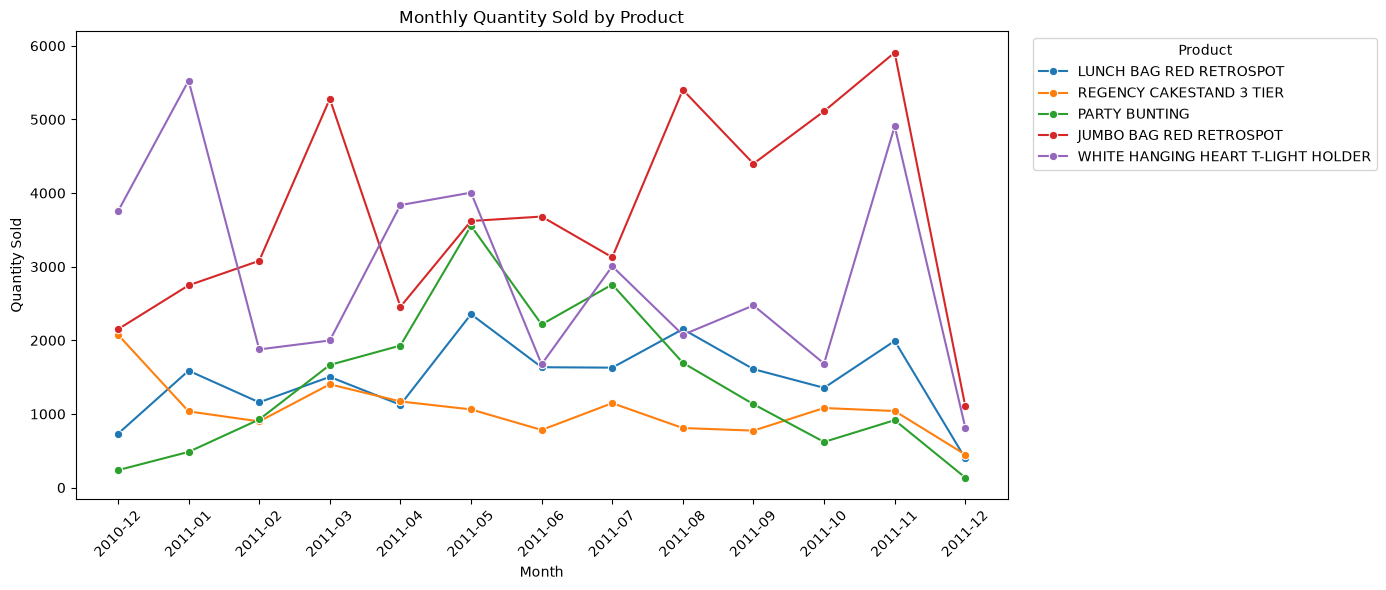

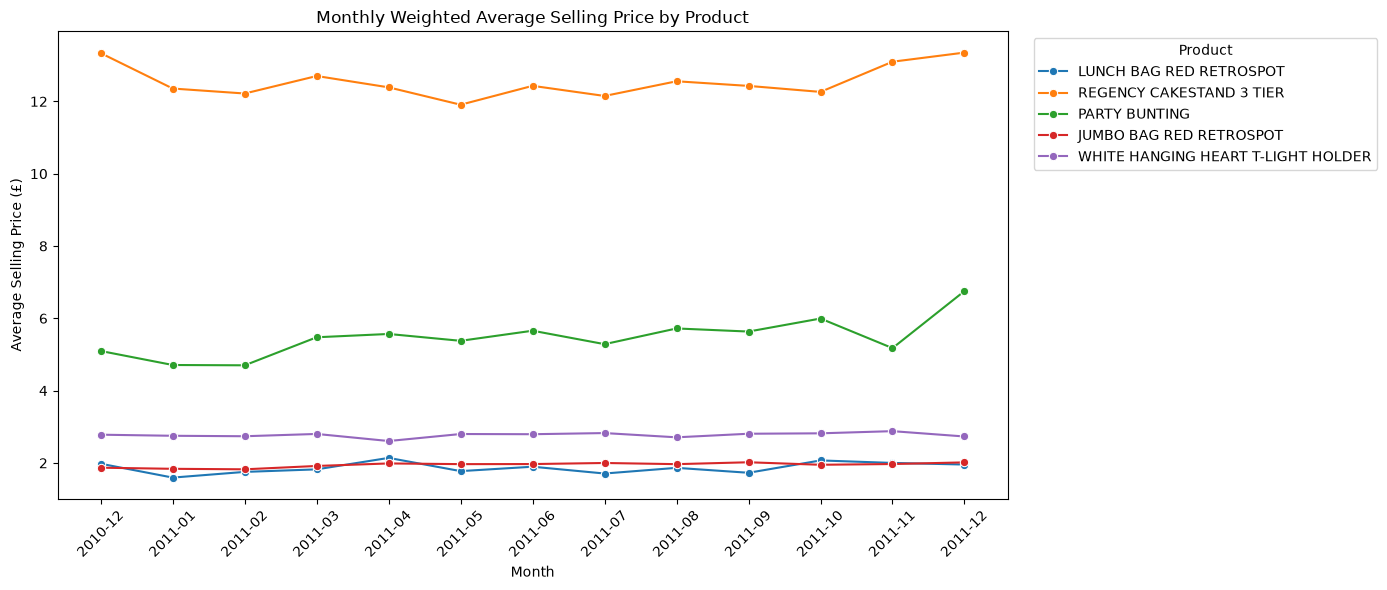

In [6]:
# Prepare monthly trends
monthly_product_analysis["Month"] = (
    monthly_product_analysis["InvoiceDate"].dt.strftime("%Y-%m")
)

# Chart 1: Monthly quantity sold
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_product_analysis,
    x="Month",
    y="quantity_sold",
    hue="Description",
    marker="o"
)

plt.title("Monthly Quantity Sold by Product")
plt.xlabel("Month")
plt.ylabel("Quantity Sold")
plt.xticks(rotation=45)
plt.legend(title="Product", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()


# Chart 2: Monthly weighted average selling price
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_product_analysis,
    x="Month",
    y="weighted_average_price",
    hue="Description",
    marker="o"
)

plt.title("Monthly Weighted Average Selling Price by Product")
plt.xlabel("Month")
plt.ylabel("Average Selling Price (£)")
plt.xticks(rotation=45)
plt.legend(title="Product", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

In [7]:
price_quantity_correlation = (
    monthly_product_analysis
    .groupby(["StockCode", "Description"])
    .apply(
        lambda group: group["weighted_average_price"].corr(
            group["quantity_sold"]
        ),
        include_groups=False
    )
    .reset_index(name="price_quantity_correlation")
)

display(price_quantity_correlation.round(3))

,StockCode,Description,price_quantity_correlation
0,20725,LUNCH BAG RED RETROSPOT,-0.339
1,22423,REGENCY CAKESTAND 3 TIER,0.198
2,47566,PARTY BUNTING,-0.092
3,85099B,JUMBO BAG RED RETROSPOT,0.119
4,85123A,WHITE HANGING HEART T-LIGHT HOLDER,0.082


In [8]:
from scipy.stats import pearsonr

correlation_results = []

for (code, description), group in monthly_product_analysis.groupby(
    ["StockCode", "Description"]
):
    r, p = pearsonr(
        group["weighted_average_price"],
        group["quantity_sold"]
    )

    correlation_results.append({
        "StockCode": code,
        "Description": description,
        "Correlation": r,
        "P_value": p
    })

correlation_results = pd.DataFrame(correlation_results)

display(correlation_results.round(4))

,StockCode,Description,Correlation,P_value
0,20725,LUNCH BAG RED RETROSPOT,-0.3388,0.2575
1,22423,REGENCY CAKESTAND 3 TIER,0.1984,0.5158
2,47566,PARTY BUNTING,-0.0916,0.7660
3,85099B,JUMBO BAG RED RETROSPOT,0.1192,0.6982
4,85123A,WHITE HANGING HEART T-LIGHT HOLDER,0.0815,0.7911


In [9]:
import numpy as np
import pandas as pd
from scipy.stats import t

analysis_df = monthly_product_analysis.copy()

# Log transformations
analysis_df = analysis_df[
    (analysis_df["quantity_sold"] > 0) &
    (analysis_df["weighted_average_price"] > 0)
].copy()

analysis_df["log_quantity"] = np.log(analysis_df["quantity_sold"])
analysis_df["log_price"] = np.log(
    analysis_df["weighted_average_price"]
)

# Product and calendar-month fixed effects
product_dummies = pd.get_dummies(
    analysis_df["StockCode"], drop_first=True, dtype=float
)

month_dummies = pd.get_dummies(
    analysis_df["InvoiceDate"], drop_first=True, dtype=float
)

X = np.column_stack([
    np.ones(len(analysis_df)),
    analysis_df["log_price"].to_numpy(),
    product_dummies.to_numpy(),
    month_dummies.to_numpy()
])

y = analysis_df["log_quantity"].to_numpy()

# Estimate regression
coefficients, _, _, _ = np.linalg.lstsq(X, y, rcond=None)

residuals = y - X @ coefficients
n, k = X.shape
degrees_of_freedom = n - k

residual_variance = (residuals @ residuals) / degrees_of_freedom
covariance = residual_variance * np.linalg.inv(X.T @ X)

price_coefficient = coefficients[1]
standard_error = np.sqrt(covariance[1, 1])

t_statistic = price_coefficient / standard_error
p_value = 2 * t.sf(abs(t_statistic), degrees_of_freedom)

print("Observations:", n)
print("Degrees of freedom:", degrees_of_freedom)
print("Price coefficient:", round(price_coefficient, 4))
print("Standard error:", round(standard_error, 4))
print("T-statistic:", round(t_statistic, 4))
print("P-value:", round(p_value, 4))

Observations: 65
Degrees of freedom: 47
Price coefficient: 0.3416
Standard error: 1.2339
T-statistic: 0.2769
P-value: 0.7831


In [10]:
# Final data-quality validation
print("Dataset shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())

print("\nMissing values:")
print(df.isnull().sum())

print("\nInvalid quantities:", (df["Quantity"] <= 0).sum())
print("Invalid prices:", (df["UnitPrice"] <= 0).sum())

revenue_difference = (
    df["Revenue"] - df["Quantity"] * df["UnitPrice"]
).abs()

print(
    "Revenue calculation errors:",
    (revenue_difference > 0.000001).sum()
)

print("\nDate range:")
print(df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())

Dataset shape: (521917, 9)
Duplicate rows: 0

Missing values:
InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     131420
Country             0
Revenue             0
dtype: int64

Invalid quantities: 0
Invalid prices: 0
Revenue calculation errors: 0

Date range:
2010-12-01 08:26:00 to 2011-12-09 12:50:00


In [11]:
print("Quantity distribution:")
display(df["Quantity"].describe(
    percentiles=[0.50, 0.90, 0.95, 0.99, 0.999]
))

print("\nUnit price distribution:")
display(df["UnitPrice"].describe(
    percentiles=[0.50, 0.90, 0.95, 0.99, 0.999]
))

print("\nHighest quantity transactions:")
display(
    df.nlargest(10, "Quantity")[
        ["StockCode", "Description", "Quantity", "UnitPrice", "Revenue"]
    ]
)

print("\nHighest price transactions:")
display(
    df.nlargest(10, "UnitPrice")[
        ["StockCode", "Description", "Quantity", "UnitPrice", "Revenue"]
    ]
)

Quantity distribution:


count    521917.000000
mean         10.319599
std          37.514866
min           1.000000
50%           4.000000
90%          24.000000
95%          30.000000
99%         100.000000
99.9%       432.000000
max        4800.000000
Name: Quantity, dtype: float64


Unit price distribution:


count    521917.000000
mean          3.271962
std           4.378317
min           0.001000
50%           2.080000
90%           7.620000
95%           9.950000
99%          16.630000
99.9%        33.290000
max         649.500000
Name: UnitPrice, dtype: float64


Highest quantity transactions:


,StockCode,Description,Quantity,UnitPrice,Revenue
405792,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,0.21,1008.00
198255,22197,SMALL POPCORN HOLDER,4300,0.72,3096.00
93729,22053,EMPIRE DESIGN ROSETTE,3906,0.82,3202.92
260549,18007,ESSENTIAL BALM 3.5g TIN IN ENVELOPE,3186,0.06,191.16
50667,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40
417565,16014,SMALL CHINESE STYLE SCISSOR,3000,0.32,960.00
4775,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,2880,0.18,518.40
280224,84879,ASSORTED COLOUR BIRD ORNAMENT,2880,1.45,4176.00
193497,21977,PACK OF 60 PINK PAISLEY CAKE CASES,2700,0.42,1134.00
77683,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,2592,0.21,544.32



Highest price transactions:


,StockCode,Description,Quantity,UnitPrice,Revenue
214200,22502,PICNIC BASKET WICKER 60 PIECES,60,649.5,38970.0
214201,22502,PICNIC BASKET WICKER 60 PIECES,1,649.5,649.5
4819,22655,VINTAGE RED KITCHEN CABINET,1,295.0,295.0
31176,22655,VINTAGE RED KITCHEN CABINET,1,295.0,295.0
49645,22655,VINTAGE RED KITCHEN CABINET,1,295.0,295.0
79663,22655,VINTAGE RED KITCHEN CABINET,1,295.0,295.0
114379,22656,VINTAGE BLUE KITCHEN CABINET,1,295.0,295.0
128943,22656,VINTAGE BLUE KITCHEN CABINET,1,295.0,295.0
164590,22656,VINTAGE BLUE KITCHEN CABINET,1,295.0,295.0
197920,22655,VINTAGE RED KITCHEN CABINET,1,295.0,295.0
